# 03 · Exploración de la variable dependiente: inflación

**Objetivo.** Describir la inflación anual (IPC, `FP.CPI.TOTL.ZG`) de los 193 miembros de la ONU, caracterizar los episodios extremos y evaluar los tres estadísticos con que se resume cada trayectoria nacional en 2000-2020:

- **media**: nivel promedio del período;
- **tendencia**: pendiente de la regresión lineal valor ~ año, en puntos porcentuales por año;
- **volatilidad**: desvío estándar de los residuos de esa regresión, es decir, la variabilidad alrededor de la tendencia.

También se decide qué transformación usar en el modelado y se contrasta el IPC con el deflactor del PIB (`NY.GDP.DEFL.KD.ZG`), la variable dependiente alternativa.

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from inflacion.config import Paths, load_params
from inflacion.viz import CATEGORICAL, CLUSTER_COLORS, DIM_LABELS, DIMENSION_COLORS, apply_theme, heatmap, show, subtitle
from inflacion.viz.theme import DIVERGING, INK_MUTED, INK_SECONDARY, SEQUENTIAL_BLUE

apply_theme()
P = load_params()
D = Paths.processed
pd.set_option("display.precision", 3)
from inflacion.sources.countries import un_members

members = un_members().set_index("iso3")
panel = pd.read_parquet(D / "panel_largo.parquet")
cpi = panel[panel["codigo"] == P["targets"]["principal"]].pivot(index="iso3", columns="anio", values="valor")
target = pd.read_csv(D / "target_principal.csv", index_col="iso3").dropna(subset=["media"])
deflator = pd.read_csv(D / "target_secundario.csv", index_col="iso3").dropna(subset=["media"])
window = cpi.loc[:, 2000:2020]
annual = window.stack().dropna()
print(f"IPC 2000-2020: {window.notna().any(axis=1).sum()} países con algún dato · {len(annual):,} observaciones país-año")
print(f"Países con trayectoria calculable (≥{P['trayectorias']['min_anios']} años): {len(target)}")

IPC 2000-2020: 184 países con algún dato · 3,672 observaciones país-año
Países con trayectoria calculable (≥5 años): 181


## 1. Cobertura de la serie de inflación

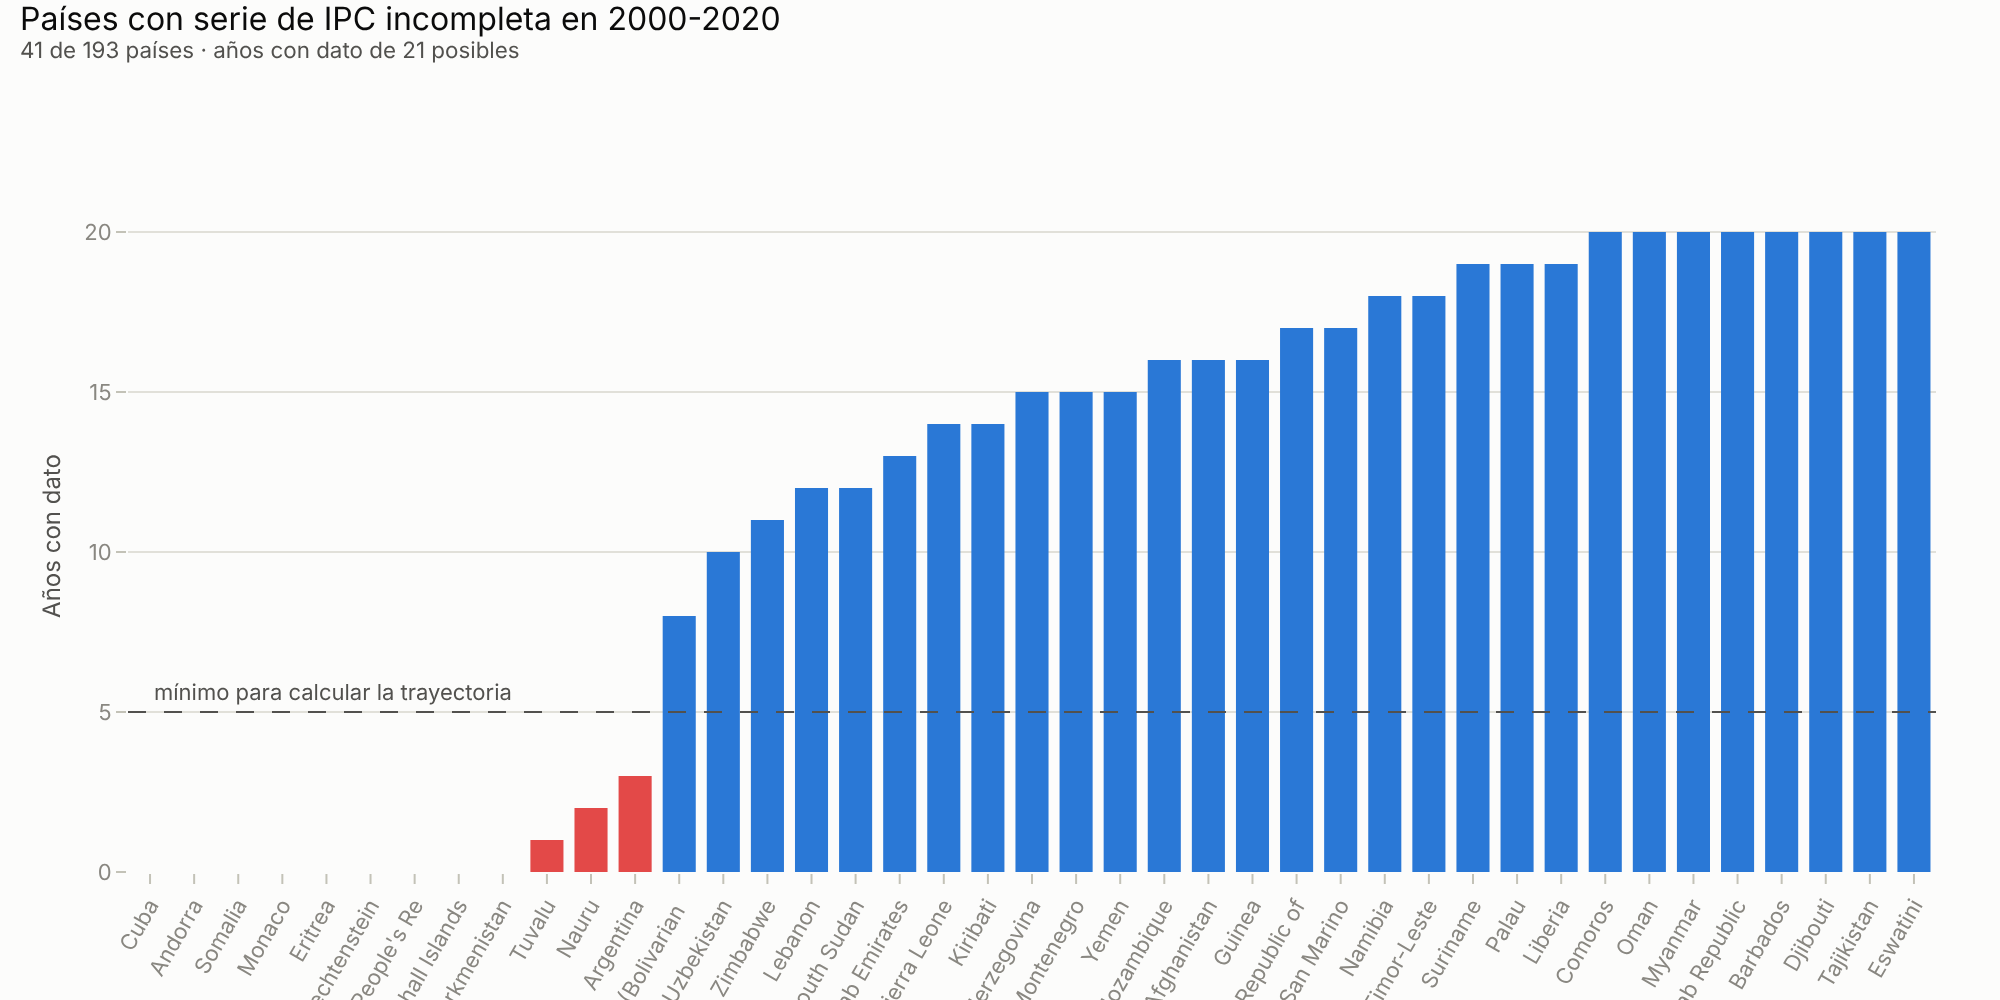

ARG: 3 años (2018-2020)
VEN: 8 años (2009-2016)
ZWE: 11 años (2010-2020)


In [2]:
n_years = window.notna().sum(axis=1).reindex(members.index).fillna(0).astype(int)
gaps = n_years[n_years < 21].sort_values()
fig = go.Figure(go.Bar(x=[members.loc[i, "pais"][:22] for i in gaps.index], y=gaps.values,
                       marker_color=np.where(gaps < P["trayectorias"]["min_anios"], CATEGORICAL[7], CATEGORICAL[0]),
                       hovertemplate="%{x}: %{y} años<extra></extra>"))
fig.add_hline(y=P["trayectorias"]["min_anios"], line=dict(color=INK_SECONDARY, dash="dash", width=1))
fig.add_annotation(x=0, y=P["trayectorias"]["min_anios"], text="mínimo para calcular la trayectoria", showarrow=False,
                   xanchor="left", yshift=10, font=dict(size=11, color=INK_SECONDARY))
fig.update_layout(title=subtitle("Países con serie de IPC incompleta en 2000-2020", f"{len(gaps)} de 193 países · años con dato de 21 posibles"),
                  yaxis=dict(title="Años con dato", range=[0, 21]), xaxis=dict(tickangle=-60, showgrid=False))
show(fig, "03_cobertura_ipc", width=1000, height=500)
for iso in ["ARG", "VEN", "ZWE"]:
    yrs = window.loc[iso].dropna().index
    print(f"{iso}: {len(yrs)} años ({yrs.min()}-{yrs.max()})" if len(yrs) else f"{iso}: sin datos")

**Interpretación.** La serie de IPC cubre 184 países en 2000-2020 y en 181 alcanza para calcular una trayectoria (mínimo 5 años). Los huecos no son aleatorios: **coinciden con los episodios más extremos o con estadísticas oficiales cuestionadas**. Argentina solo tiene 2018-2020 en WDI: los años anteriores, que incluyen el período de intervención del INDEC (2007-2015), no figuran en la base. A Venezuela le faltan los años de hiperinflación posteriores a 2016, y a Zimbabue los de 2000-2009.

**Implicancia.** La muestra del IPC subrepresenta las trayectorias más extremas, así que la heterogeneidad observada es, si algo, una cota inferior de la real. Argentina, el caso que motiva la tesis, queda fuera del análisis principal. Se recupera en la especificación alternativa con el deflactor del PIB, que cubre 192 países (notebook 08).

## 2. Evolución temporal y distribución anual

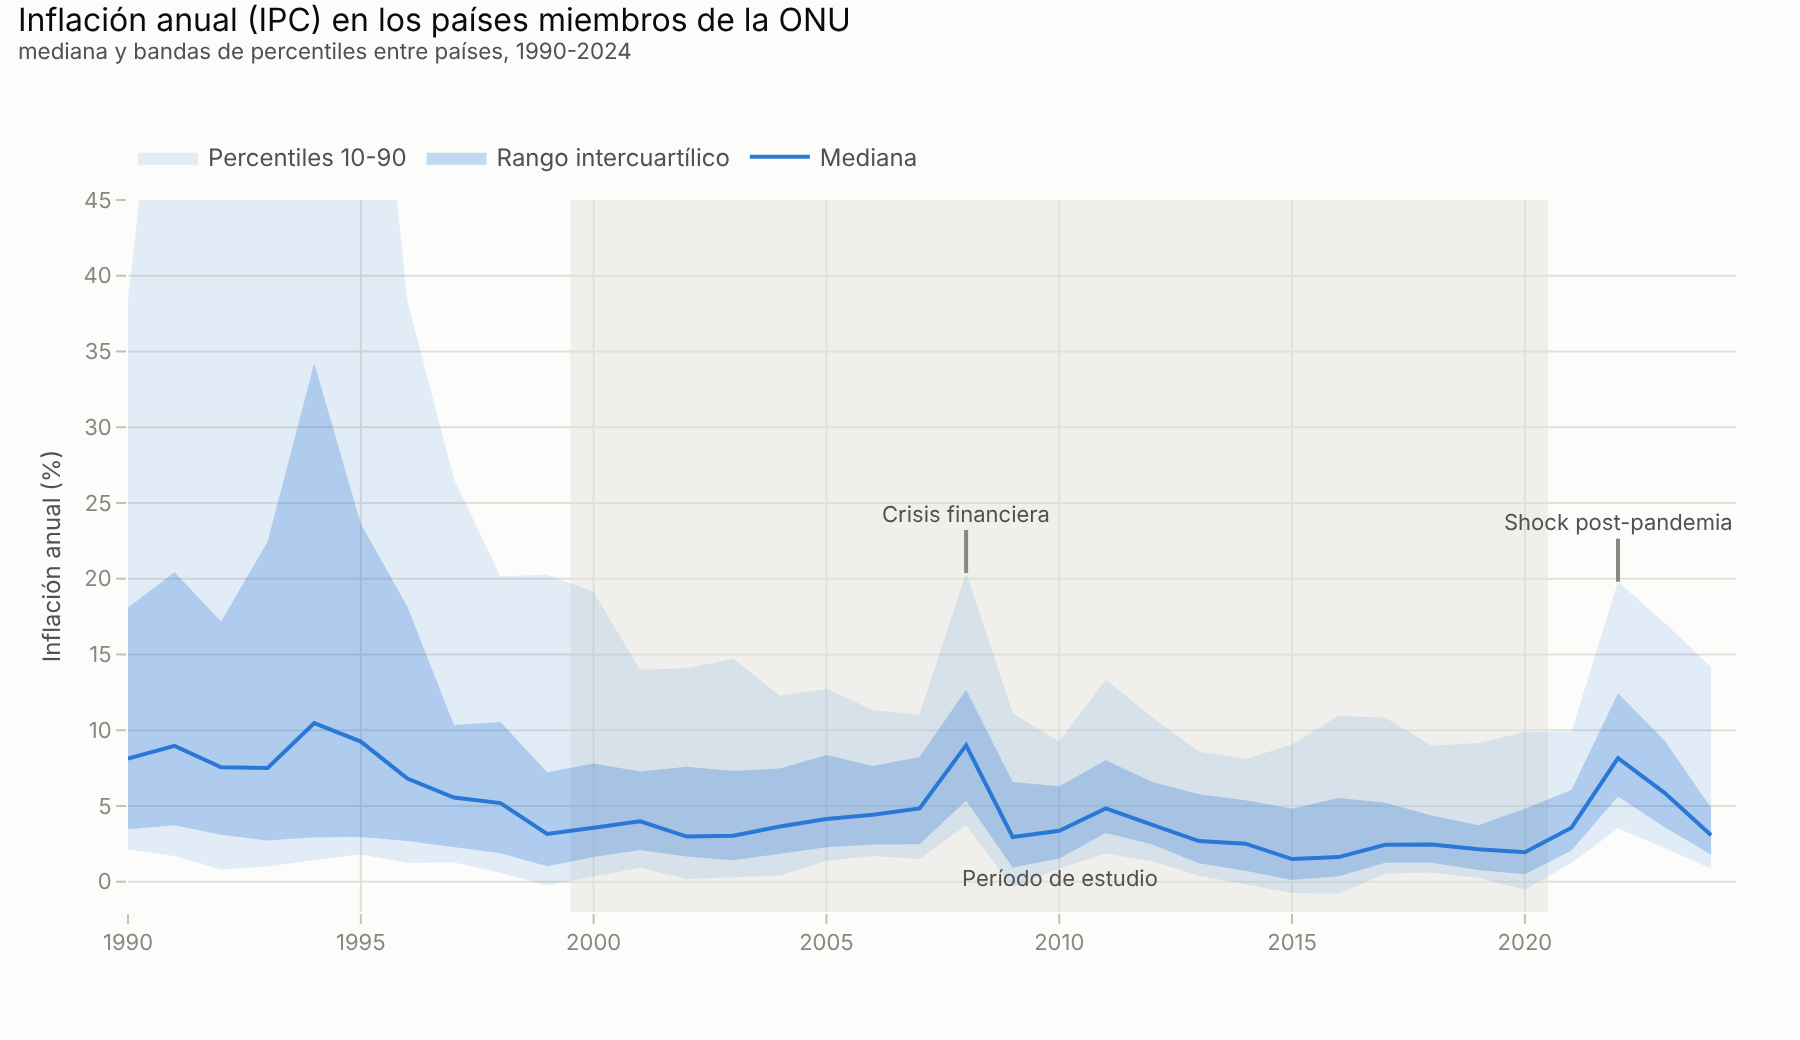

      0.25  0.50   0.75
anio                   
1990  3.46  8.13  18.10
1995  2.96  9.25  23.63
2000  1.63  3.56   7.81
2008  5.34  9.01  12.67
2010  1.52  3.36   6.30
2015  0.11  1.49   4.82
2020  0.50  1.94   4.82
2022  5.62  8.16  12.44
2024  1.79  3.07   4.88


In [3]:
yrs = range(1990, 2025)
q = cpi.loc[:, yrs].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).T
fig = go.Figure()
fig.add_vrect(x0=1999.5, x1=2020.5, fillcolor='#f0efec', opacity=1, line_width=0, layer="below")
fig.add_scatter(x=list(q.index) + list(q.index[::-1]), y=list(q[0.9]) + list(q[0.1][::-1]), fill="toself",
                fillcolor="rgba(42,120,214,0.12)", line=dict(width=0), name="Percentiles 10-90", hoverinfo="skip")
fig.add_scatter(x=list(q.index) + list(q.index[::-1]), y=list(q[0.75]) + list(q[0.25][::-1]), fill="toself",
                fillcolor="rgba(42,120,214,0.28)", line=dict(width=0), name="Rango intercuartílico", hoverinfo="skip")
fig.add_scatter(x=q.index, y=q[0.5], name="Mediana", mode="lines", line=dict(color=CATEGORICAL[0]),
                hovertemplate="%{x}: mediana %{y:.1f}%<extra></extra>")
for x, txt in [(2008, "Crisis financiera"), (2022, "Shock post-pandemia")]:
    fig.add_annotation(x=x, y=q.loc[x, 0.9], text=txt, showarrow=True, arrowhead=0, ay=-30, ax=0,
                       font=dict(size=11, color=INK_SECONDARY), arrowcolor=INK_MUTED)
fig.add_annotation(x=2010, y=0, yref="paper", text="Período de estudio", showarrow=False, yshift=8, font=dict(size=11, color=INK_SECONDARY))
fig.update_layout(title=subtitle("Inflación anual (IPC) en los países miembros de la ONU", "mediana y bandas de percentiles entre países, 1990-2024"),
                  yaxis=dict(title="Inflación anual (%)", range=[-2, 45]), xaxis_title=None)
show(fig, "03_inflacion_temporal")
print(q.loc[[1990, 1995, 2000, 2008, 2010, 2015, 2020, 2022, 2024], [0.25, 0.5, 0.75]].round(2))

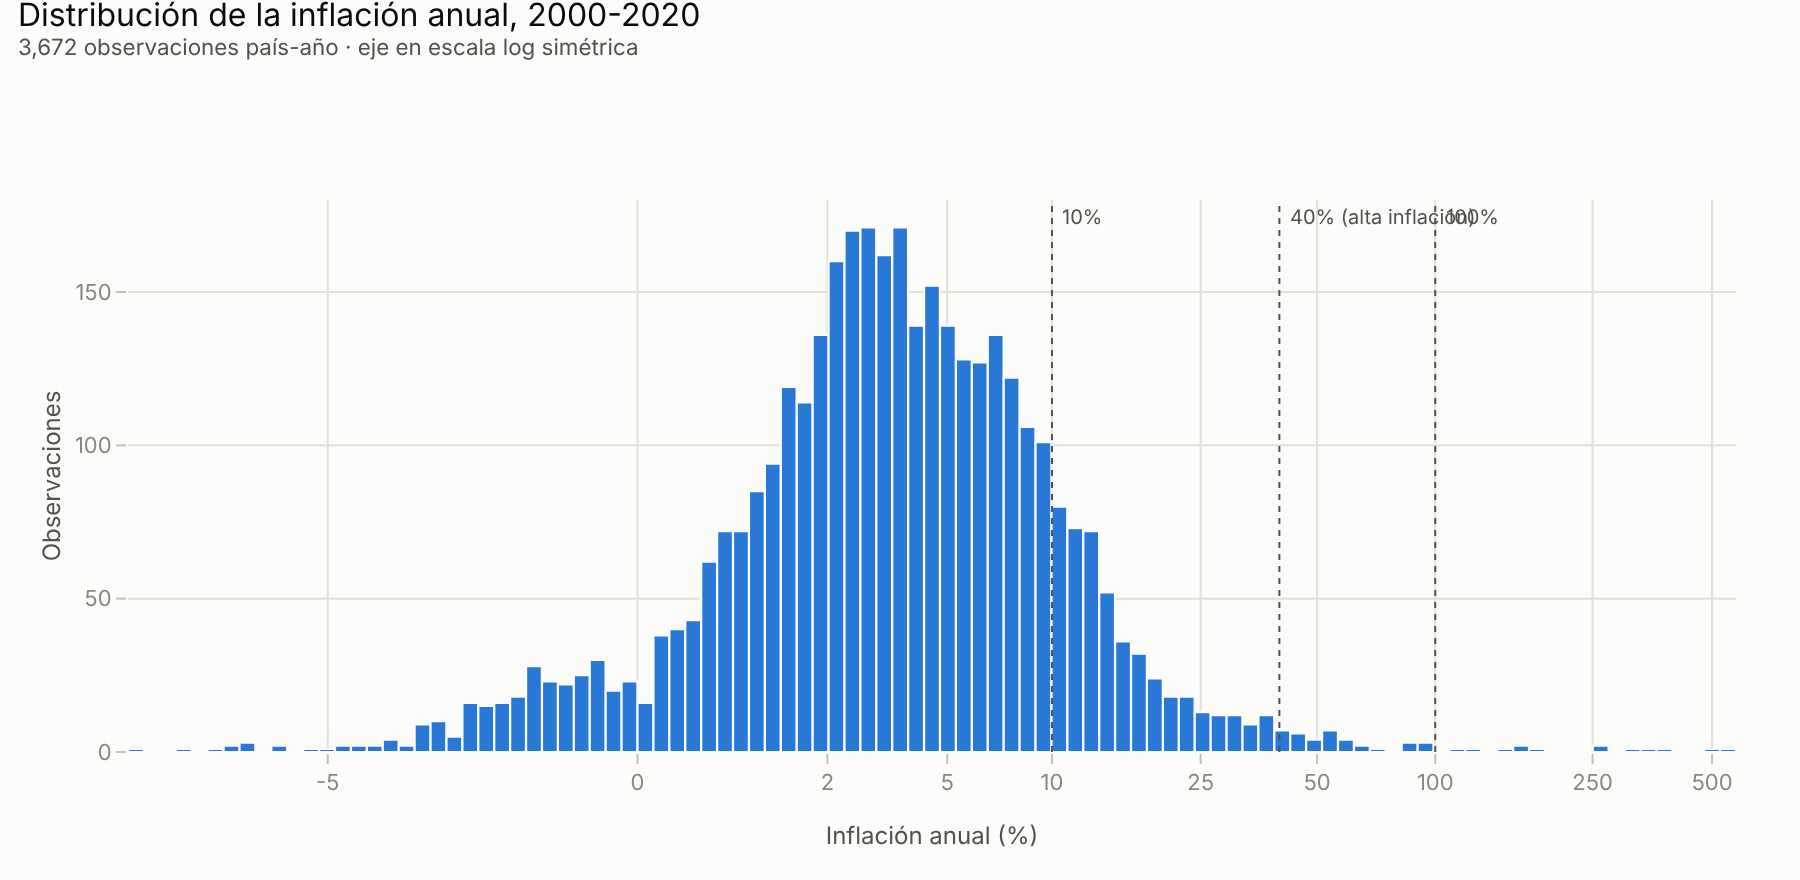

Percentiles: {0.01: -2.17, 0.05: -0.46, 0.25: 1.5, 0.5: 3.35, 0.75: 6.87, 0.95: 17.15, 0.99: 47.1}
Deflación (<0%): 7.7% · >40%: 49 obs en 21 países · >100%: 13 obs


In [4]:
def slog(x):
    return np.sign(x) * np.log10(1 + np.abs(x))

ticks = np.array([-5, 0, 2, 5, 10, 25, 50, 100, 250, 500])
fig = go.Figure(go.Histogram(x=slog(annual), xbins=dict(size=0.04), marker_color=CATEGORICAL[0],
                             hovertemplate="%{y} observaciones<extra></extra>"))
for v, lab in [(10, "10%"), (40, "40% (alta inflación)"), (100, "100%")]:
    fig.add_vline(x=slog(v), line=dict(color=INK_SECONDARY, dash="dot", width=1))
    fig.add_annotation(x=slog(v), y=1, yref="paper", text=lab, showarrow=False, xanchor="left", xshift=3, font=dict(size=10, color=INK_SECONDARY))
fig.update_layout(title=subtitle("Distribución de la inflación anual, 2000-2020", f"{len(annual):,} observaciones país-año · eje en escala log simétrica"),
                  xaxis=dict(title="Inflación anual (%)", tickvals=slog(ticks), ticktext=[str(t) for t in ticks]),
                  yaxis_title="Observaciones", bargap=0.02)
show(fig, "03_distribucion_anual", height=440)
pct = annual.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(2)
print("Percentiles:", pct.to_dict())
print(f"Deflación (<0%): {(annual < 0).mean():.1%} · >40%: {(annual > 40).sum()} obs en {annual[annual > 40].index.get_level_values(0).nunique()} países · >100%: {(annual > 100).sum()} obs")

**Interpretación.** La distribución anual está muy sesgada a la derecha: la mediana es 3,4% y el RIC 1,5-6,9%, pero el percentil 99 llega a 47%. El 7,7% de las observaciones son deflación. Hay 49 años-país por encima del 40% (umbral convencional de alta inflación) en 21 países, y 13 por encima del 100%. Estos valores no son errores de medición: son episodios reales, y su peso desproporcionado en cualquier promedio justifica trabajar con transformaciones logarítmicas y con estimadores robustos de la tendencia.

**Interpretación.** La mediana entre países pasa de 8-9% a comienzos de los 90 a 3,6% en 2000. El período de estudio arranca, entonces, después de la gran desinflación de las economías en transición y de América Latina. Dentro de la ventana, la inflación típica es baja y bastante estable (mediana entre 1,5% y 5%), con un salto en 2008 por el shock de precios de alimentos y energía (mediana 9,0%). El shock post-pandemia de 2022 (mediana 8,2%) queda fuera de la ventana. La dispersión entre países, en cambio, nunca desaparece: el percentil 90 se mantiene entre 9% y 20% durante todo el período.

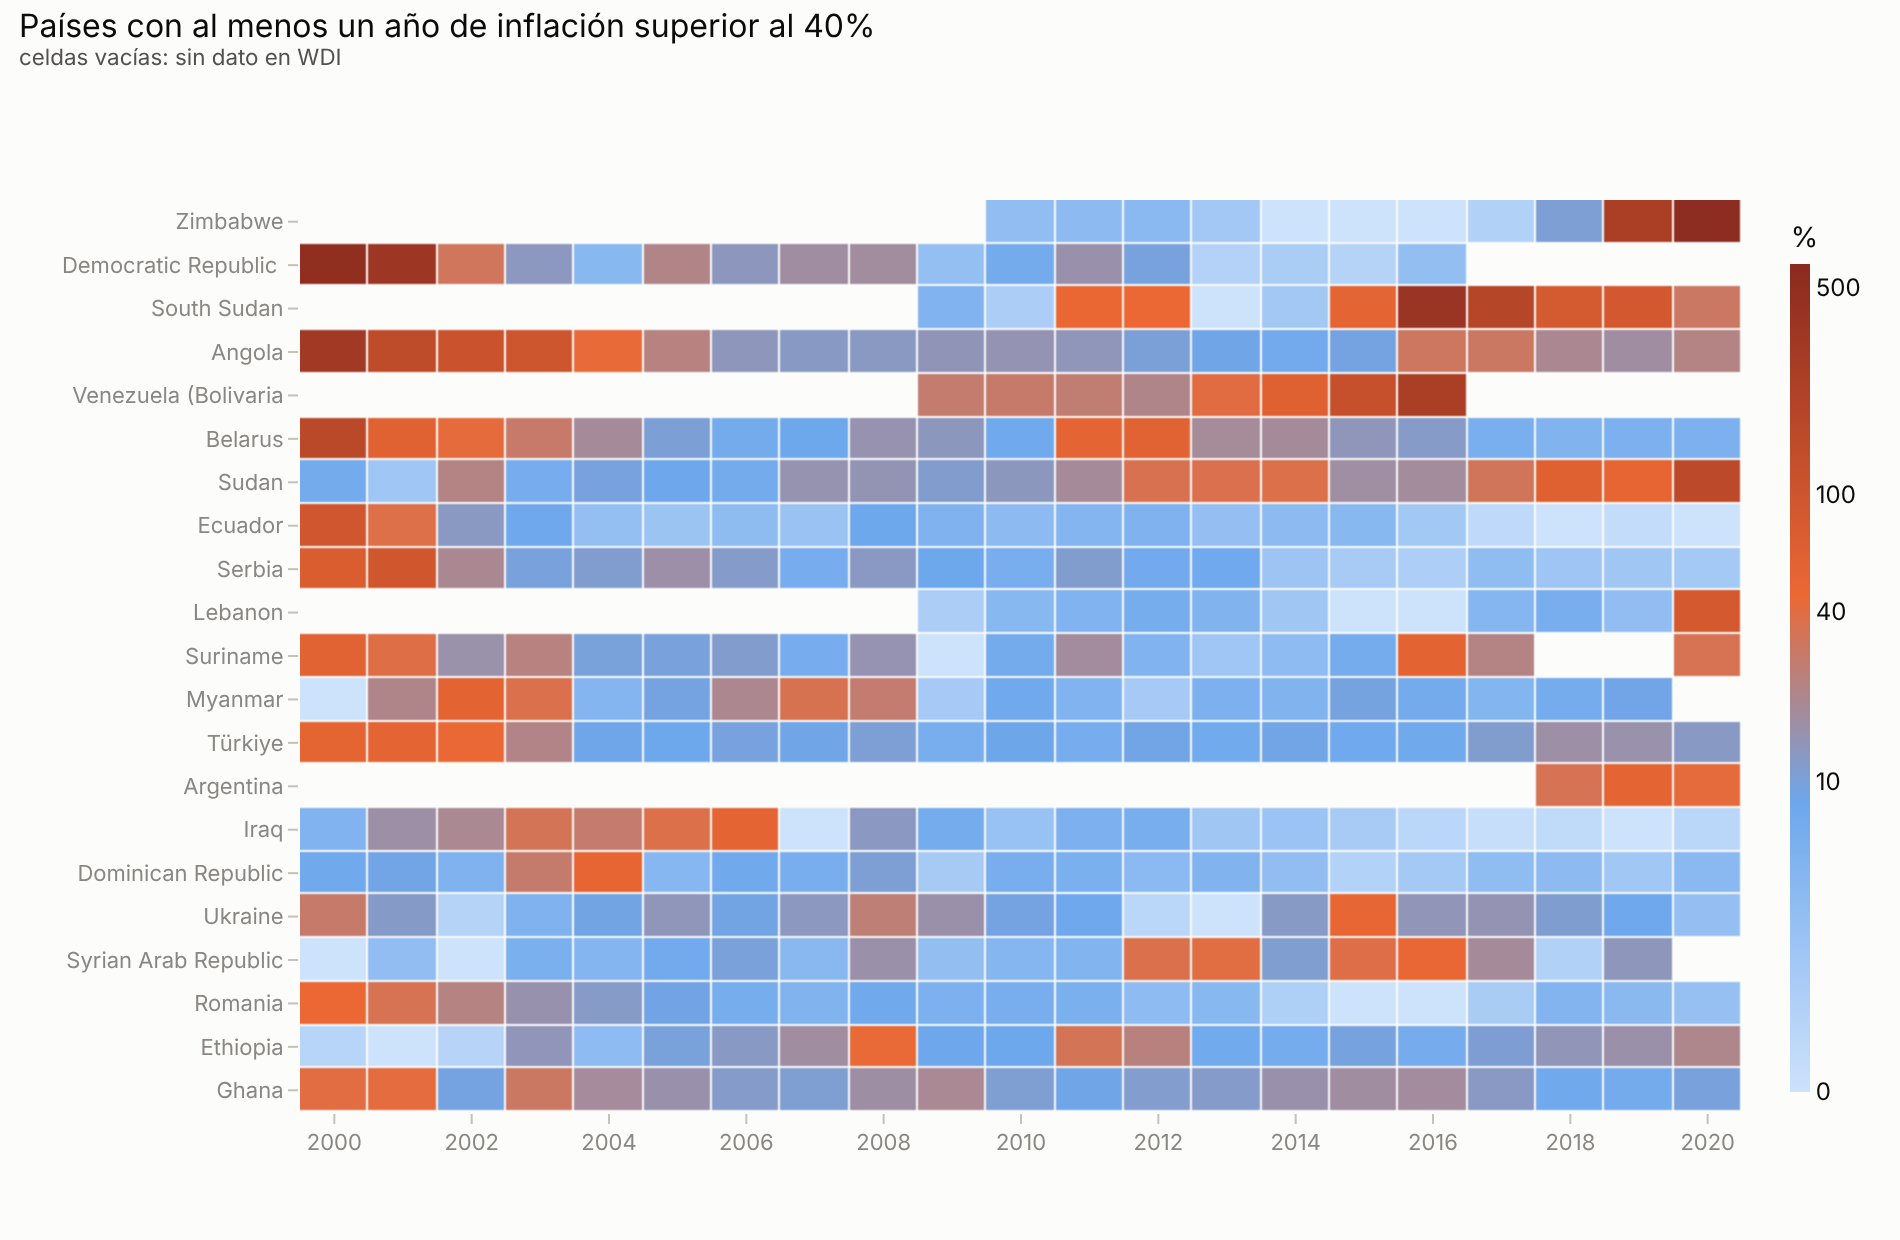

iso3  anio
SSD   2017    188.0
VEN   2016    255.0
ZWE   2019    255.0
AGO   2000    325.0
COD   2001    360.0
SSD   2016    380.0
COD   2000    514.0
ZWE   2020    557.0
dtype: float64


In [5]:
hi = annual[annual > 40].index.get_level_values(0).unique()
H = window.loc[hi]
H = H.loc[H.max(axis=1).sort_values(ascending=False).index]
z = slog(H.values)
fig = go.Figure(go.Heatmap(z=z, x=list(H.columns), y=[members.loc[i, "pais"][:20] for i in H.index],
                           colorscale=[[0, "#cde2fb"], [0.35, "#6da7ec"], [0.6, "#eb6834"], [1, "#8a2a1f"]], zmin=0, zmax=slog(600),
                           customdata=H.values, hovertemplate="%{y} %{x}: %{customdata:.1f}%<extra></extra>", xgap=1, ygap=1,
                           colorbar=dict(title="%", tickvals=slog(np.array([0, 10, 40, 100, 500])), ticktext=["0", "10", "40", "100", "500"],
                                         thickness=10, outlinewidth=0)))
fig.update_layout(title=subtitle("Países con al menos un año de inflación superior al 40%", "celdas vacías: sin dato en WDI"),
                  xaxis=dict(showgrid=False, dtick=2), yaxis=dict(showgrid=False, autorange="reversed"), margin=dict(l=150))
show(fig, "03_episodios_alta_inflacion", width=950, height=620)
print(annual.sort_values().tail(8).round(0))

**Interpretación.** Los episodios de alta inflación forman dos grupos temporales. El primero está al comienzo del período (2000-2004): son colas de desinflaciones iniciadas en los 90 en Angola, Congo RD, Belarús, Serbia, Turquía, Ecuador y Rumania. El segundo es posterior a 2011 y se asocia a conflicto armado o colapso macroeconómico: Sudán del Sur, Venezuela, Sudán, Siria, Líbano, Zimbabue y Argentina en 2019-2020. Este patrón importa para los estadísticos de trayectoria: un episodio al inicio de la serie produce tendencias muy negativas (Congo RD: −16,8 p.p./año) y uno al final, tendencias muy positivas (Zimbabue: +34,5 p.p./año).

## 3. Estadísticos de trayectoria por país

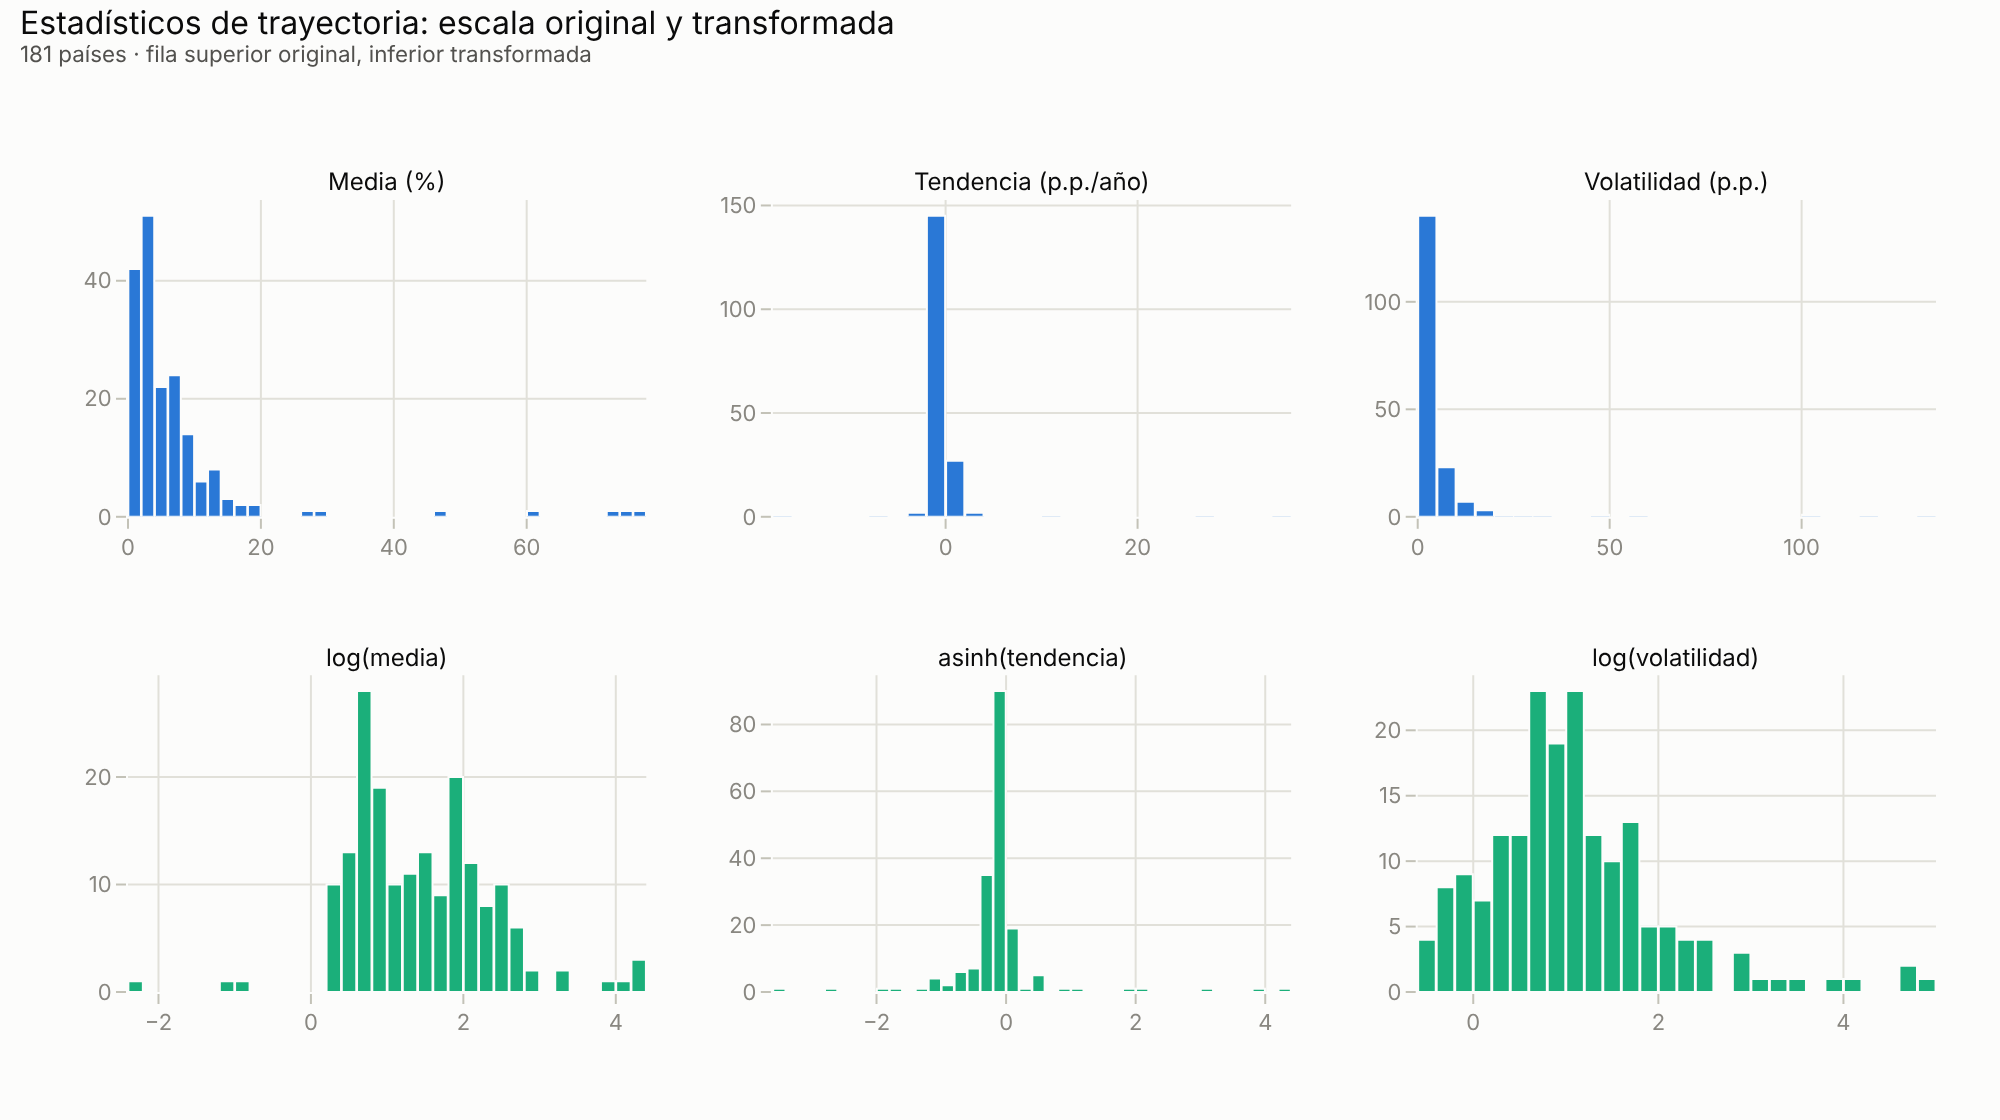

Asimetría:
             original  transformada
media            4.73          0.32
tendencia        6.28          1.96
volatilidad      6.14          1.26
        media  tendencia  volatilidad
count  181.00     181.00       181.00
mean     6.98       0.11         6.31
std     11.20       3.65        16.13
min      0.10     -16.83         0.59
25%      2.06      -0.28         1.64
50%      3.87      -0.12         2.64
75%      7.00      -0.03         4.41
max     76.77      34.51       134.88


In [6]:
TR = {"media": ("log(media)", np.log),
      "tendencia": ("asinh(tendencia)", np.arcsinh),
      "volatilidad": ("log(volatilidad)", np.log)}
fig = make_subplots(rows=2, cols=3, vertical_spacing=0.2, horizontal_spacing=0.07,
                    subplot_titles=["Media (%)", "Tendencia (p.p./año)", "Volatilidad (p.p.)"] + [t for t, _ in TR.values()])
for c, (stat, (lab, f)) in enumerate(TR.items(), start=1):
    fig.add_histogram(x=target[stat], nbinsx=40, marker_color=CATEGORICAL[0], showlegend=False, row=1, col=c)
    fig.add_histogram(x=f(target[stat]), nbinsx=40, marker_color=CATEGORICAL[2], showlegend=False, row=2, col=c)
fig.update_annotations(font_size=12)
fig.update_layout(title=subtitle("Estadísticos de trayectoria: escala original y transformada",
                                 f"{len(target)} países · fila superior original, inferior transformada"), bargap=0.05)
show(fig, "03_trayectorias_transformaciones", width=1000, height=560)
skew = pd.DataFrame({"original": target[list(TR)].skew(), "transformada": pd.Series({s: f(target[s]).skew() for s, (_, f) in TR.items()})})
print("Asimetría:"); print(skew.round(2))
print(target[list(TR)].describe().round(2))

**Interpretación y decisión.** Los tres estadísticos tienen asimetrías extremas en su escala original (4,7 a 6,3). Las transformaciones elegidas son:

- **media → log(media)**: la asimetría baja de 4,73 a 0,32. Es aplicable porque todas las medias son positivas (mínimo 0,10%, Japón). La tesis usaba log(1 + media/100), pero para inflaciones típicas esa función es casi lineal y deja la asimetría en 4,18, es decir, prácticamente no transforma.
- **tendencia → asinh(tendencia)**: es la transformación logarítmica que admite valores negativos. Reduce la asimetría de 6,28 a 1,96, y la cola que queda corresponde a los episodios extremos de inicio y fin de período.
- **volatilidad → log(volatilidad)**: la asimetría baja de 6,14 a 1,26.

Estas son las variables dependientes de los modelos de H2/H3 y de las pruebas de H1.

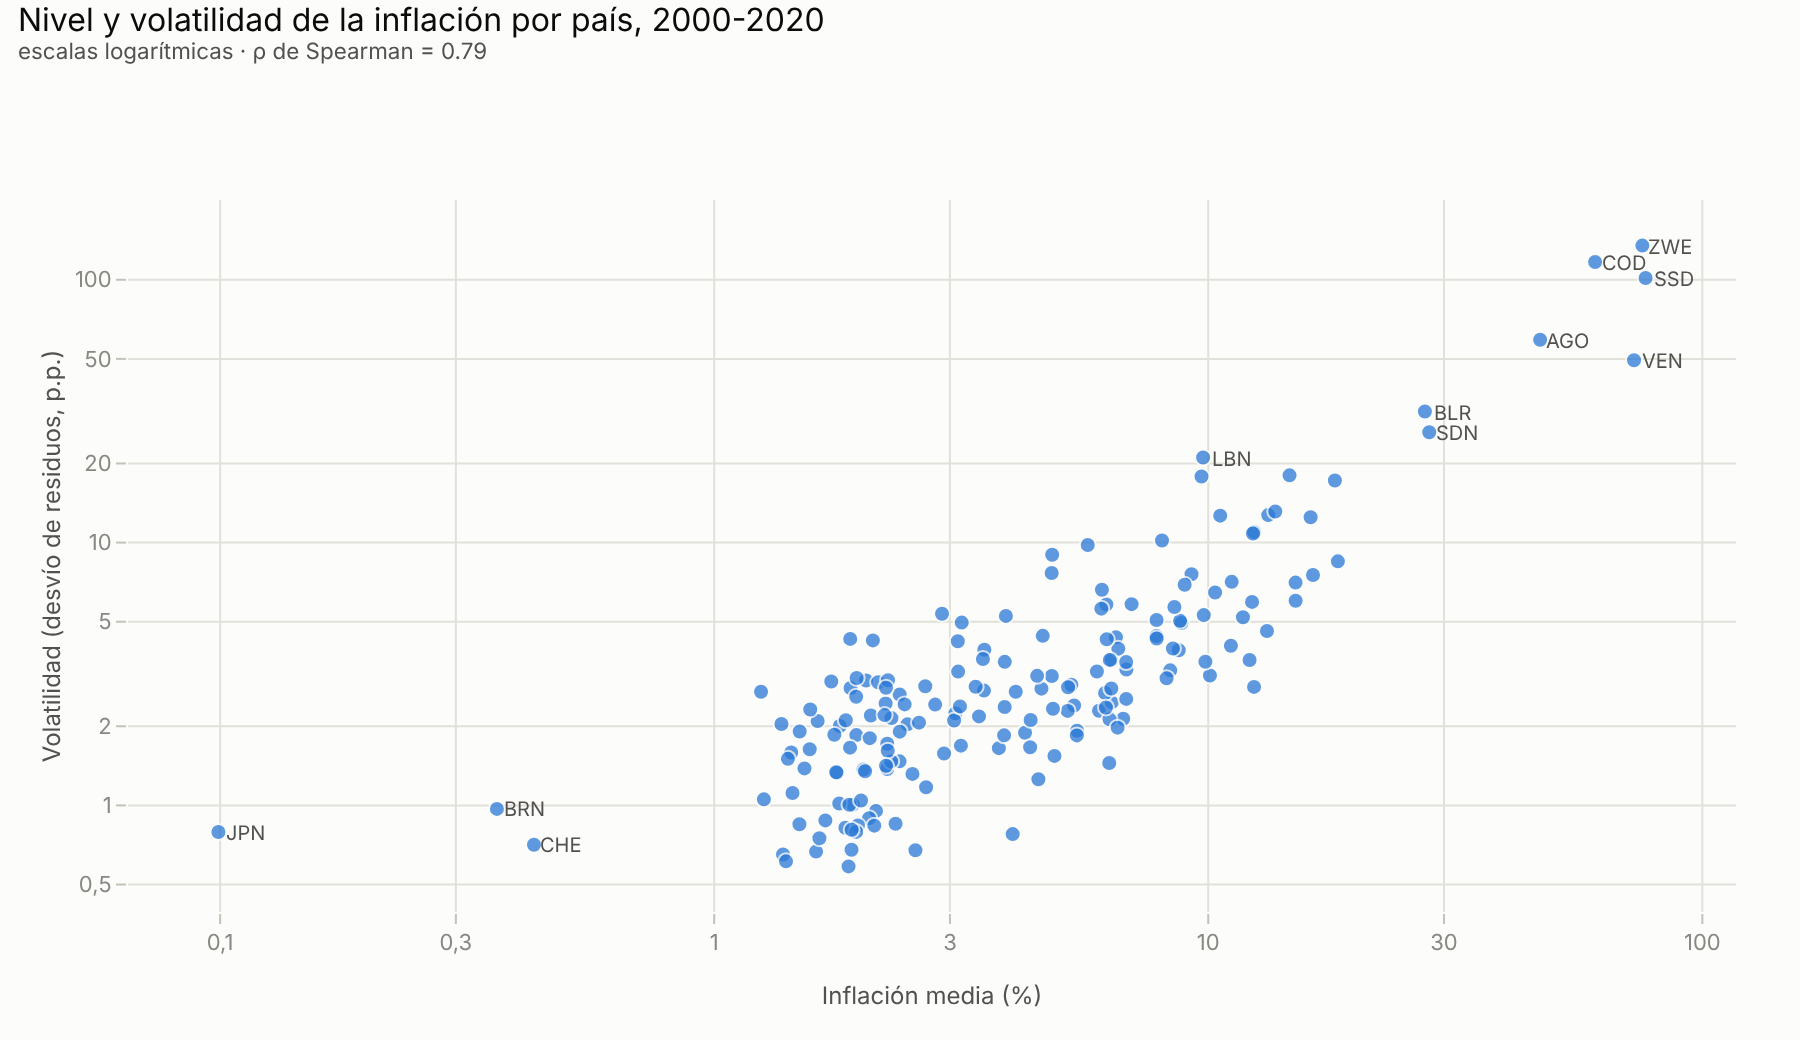

             media  tendencia  volatilidad
media        1.000     -0.168        0.786
tendencia   -0.168      1.000       -0.191
volatilidad  0.786     -0.191        1.000


In [7]:
fig = go.Figure()
reg_order = ["Africa", "Americas", "Asia", "Europe", "Oceania"]
reg_es = {"Africa": "África", "Americas": "América", "Asia": "Asia", "Europe": "Europa", "Oceania": "Oceanía"}
t = target.join(members[["pais", "region"]])
fig.add_scatter(x=t["media"], y=t["volatilidad"], mode="markers", marker=dict(size=8, color=CATEGORICAL[0], opacity=0.75),
                customdata=t["pais"], hovertemplate="%{customdata}<br>media %{x:.1f}% · volatilidad %{y:.1f}<extra></extra>", showlegend=False)
lab = t[(t["media"] > 20) | (t["volatilidad"] > 20) | (t["media"] < 0.6)]
for iso, r in lab.iterrows():
    fig.add_annotation(x=np.log10(r["media"]), y=np.log10(r["volatilidad"]), text=iso, showarrow=False, xshift=14,
                       font=dict(size=10, color=INK_SECONDARY))
rho = t[["media", "volatilidad"]].corr("spearman").iloc[0, 1]
fig.update_layout(title=subtitle("Nivel y volatilidad de la inflación por país, 2000-2020", f"escalas logarítmicas · ρ de Spearman = {rho:.2f}"),
                  xaxis=dict(type="log", title="Inflación media (%)", tickvals=[0.1, 0.3, 1, 3, 10, 30, 100], ticktext=["0,1", "0,3", "1", "3", "10", "30", "100"]),
                  yaxis=dict(type="log", title="Volatilidad (desvío de residuos, p.p.)", tickvals=[0.5, 1, 2, 5, 10, 20, 50, 100], ticktext=["0,5", "1", "2", "5", "10", "20", "50", "100"]))
show(fig, "03_media_vs_volatilidad")
print(t[["media", "tendencia", "volatilidad"]].corr("spearman").round(3))

**Interpretación.** Nivel y volatilidad están fuertemente asociados (ρ = 0,79): los países con inflación alta son también los de inflación más errática, lo cual es coherente con la literatura sobre los costos de la inflación alta. La relación es aproximadamente lineal en escala log-log, sin un umbral evidente. La tendencia, en cambio, es casi independiente de ambos (ρ = −0,17 con la media y −0,19 con la volatilidad): **los tres estadísticos capturan aspectos distintos de la trayectoria**, lo que respalda modelarlos por separado. En la cola superior aparecen los casos de colapso (Zimbabue, Congo RD, Sudán del Sur, Angola, Venezuela). En el extremo inferior, Japón, Brunéi y Suiza, con inflación media por debajo del 0,5%.

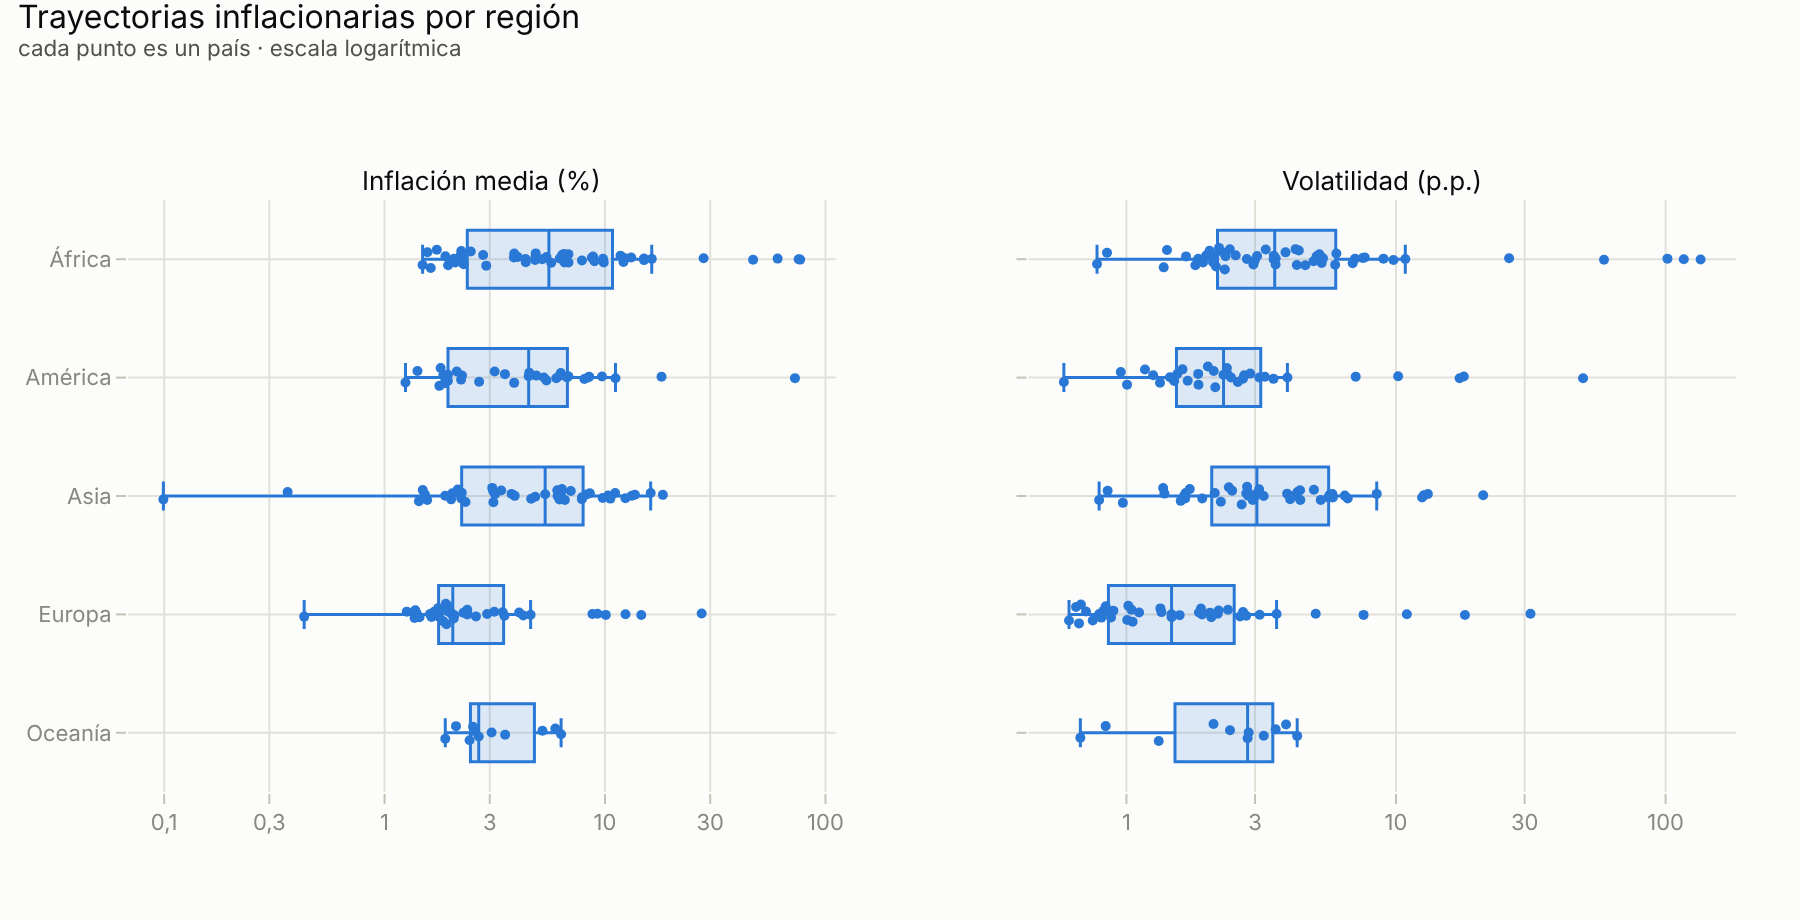

          media  volatilidad   n
region                          
Africa     5.56         3.55  52
Americas   4.50         2.29  33
Asia       5.35         3.05  45
Europe     2.04         1.47  40
Oceania    2.67         2.82  11


In [8]:
med = t.groupby("region")[["media", "volatilidad"]].median().round(2)
fig = make_subplots(rows=1, cols=2, subplot_titles=("Inflación media (%)", "Volatilidad (p.p.)"), horizontal_spacing=0.12)
for c, stat in enumerate(["media", "volatilidad"], start=1):
    for reg in reg_order:
        v = t.loc[t["region"] == reg, stat]
        fig.add_box(x=v, name=reg_es[reg], marker=dict(color=CATEGORICAL[0], size=5), line=dict(width=1.5), boxpoints="all",
                    jitter=0.4, pointpos=0, fillcolor="rgba(42,120,214,0.15)", showlegend=False,
                    customdata=t.loc[v.index, "pais"], hovertemplate="%{customdata}: %{x:.1f}<extra></extra>", row=1, col=c)
    fig.update_xaxes(type="log", tickvals=[0.1, 0.3, 1, 3, 10, 30, 100], ticktext=["0,1", "0,3", "1", "3", "10", "30", "100"], row=1, col=c)
fig.update_annotations(font_size=13)
fig.update_layout(title=subtitle("Trayectorias inflacionarias por región", "cada punto es un país · escala logarítmica"),
                  yaxis=dict(autorange="reversed"), yaxis2=dict(autorange="reversed", showticklabels=False))
show(fig, "03_por_region", height=460)
print(med.assign(n=t.groupby("region").size()))

**Interpretación.** Europa tiene la inflación mediana más baja y menos volátil (2,0% y 1,5 p.p.). África y Asia, las más altas (5,6% y 5,4%). Pero la dispersión dentro de cada región supera ampliamente las diferencias entre regiones: en todas, salvo Europa, hay países por debajo del 2% y por encima del 10%. La geografía por sí sola no ordena las trayectorias inflacionarias, lo que anticipa el planteo de H1: tampoco cabe esperar que un agrupamiento por perfil macro lo haga por completo.

## 4. Robustez de la tendencia y de la medida de inflación

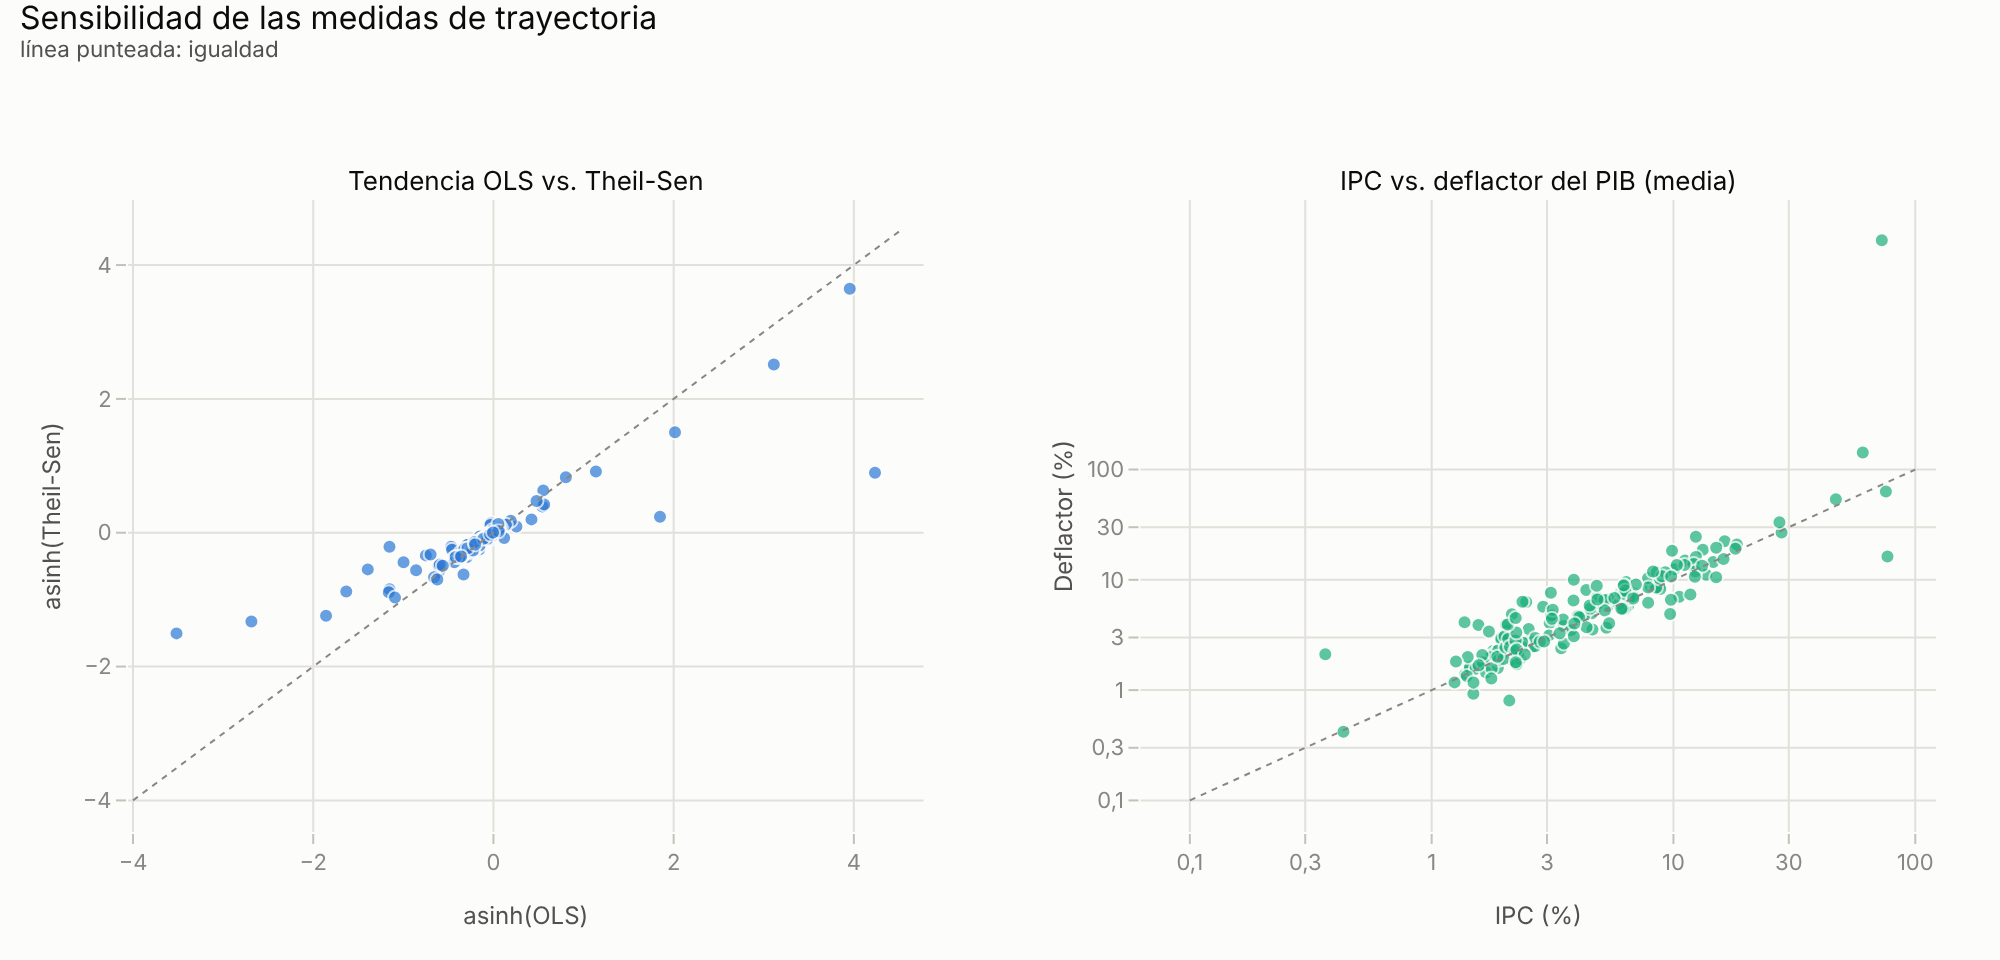

OLS vs Theil-Sen: ρ = 0.967 · mismo signo en 95.6% · rango OLS -16.8 a 34.5 · rango TS -2.1 a 19.1
IPC vs deflactor (ρ Spearman): {'media': np.float64(0.926), 'tendencia': np.float64(0.53), 'volatilidad': np.float64(0.762)}
Países con deflactor: 192 · con IPC: 181 · solo deflactor: ['AND', 'ARG', 'CUB', 'ERI', 'LIE', 'MCO', 'MHL', 'NRU', 'SOM', 'TKM', 'TUV']


In [9]:
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.12,
                    subplot_titles=("Tendencia OLS vs. Theil-Sen", "IPC vs. deflactor del PIB (media)"))
fig.add_scatter(x=np.arcsinh(t["tendencia"]), y=np.arcsinh(t["tendencia_theil_sen"]), mode="markers",
                marker=dict(size=7, color=CATEGORICAL[0], opacity=0.7), customdata=t["pais"],
                hovertemplate="%{customdata}<extra></extra>", showlegend=False, row=1, col=1)
lim = [-4, 4.5]
fig.add_scatter(x=lim, y=lim, mode="lines", line=dict(color=INK_MUTED, dash="dot", width=1), showlegend=False, hoverinfo="skip", row=1, col=1)
j = t.join(deflator[["media"]], rsuffix="_defl", how="inner")
fig.add_scatter(x=j["media"], y=j["media_defl"], mode="markers", marker=dict(size=7, color=CATEGORICAL[2], opacity=0.7),
                customdata=j["pais"], hovertemplate="%{customdata}<extra></extra>", showlegend=False, row=1, col=2)
fig.add_scatter(x=[0.1, 100], y=[0.1, 100], mode="lines", line=dict(color=INK_MUTED, dash="dot", width=1), showlegend=False, hoverinfo="skip", row=1, col=2)
fig.update_xaxes(title_text="asinh(OLS)", row=1, col=1); fig.update_yaxes(title_text="asinh(Theil-Sen)", row=1, col=1)
LT = dict(type="log", tickvals=[0.1, 0.3, 1, 3, 10, 30, 100], ticktext=["0,1", "0,3", "1", "3", "10", "30", "100"])
fig.update_xaxes(title_text="IPC (%)", row=1, col=2, **LT); fig.update_yaxes(title_text="Deflactor (%)", row=1, col=2, **LT)
fig.update_annotations(font_size=13)
fig.update_layout(title=subtitle("Sensibilidad de las medidas de trayectoria", "línea punteada: igualdad"))
show(fig, "03_robustez_medidas", width=1000, height=480)
rho_ts = t[["tendencia", "tendencia_theil_sen"]].corr("spearman").iloc[0, 1]
same_sign = (np.sign(t["tendencia"]) == np.sign(t["tendencia_theil_sen"])).mean()
print(f"OLS vs Theil-Sen: ρ = {rho_ts:.3f} · mismo signo en {same_sign:.1%} · rango OLS {t['tendencia'].min():.1f} a {t['tendencia'].max():.1f} · rango TS {t['tendencia_theil_sen'].min():.1f} a {t['tendencia_theil_sen'].max():.1f}")
jj = target.join(deflator, rsuffix="_d", how="inner")
print("IPC vs deflactor (ρ Spearman):", {s: round(jj[[s, s + "_d"]].corr("spearman").iloc[0, 1], 3) for s in ["media", "tendencia", "volatilidad"]})
print(f"Países con deflactor: {len(deflator)} · con IPC: {len(target)} · solo deflactor: {sorted(set(deflator.index) - set(target.index))}")

**Interpretación.**

- **Tendencia OLS vs. Theil-Sen.** El ordenamiento de los países es casi idéntico (ρ = 0,97, mismo signo en el 95,6%), pero la escala no: el rango OLS va de −16,8 a +34,5 p.p./año, y el de Theil-Sen de −2,1 a +19,1. El caso más claro es Zimbabue: su pendiente OLS (+34,5) la determina un único año, 2020, con 557%. La pendiente robusta es +1,0. Por eso la tendencia Theil-Sen entra como especificación alternativa en el notebook 08.
- **IPC vs. deflactor.** Coinciden mucho en el nivel (ρ = 0,93) y razonablemente en la volatilidad (0,76), pero poco en la tendencia (0,53). El deflactor mide los precios de toda la producción interna, incluidas las exportaciones de materias primas, así que su tendencia está más expuesta a los términos de intercambio. Como especificación alternativa tiene una ventaja concreta: incluye a Argentina, Cuba, Somalia y Turkmenistán, que no tienen IPC utilizable en WDI.

## Síntesis del EDA de inflación

1. La ventana 2000-2020 es un régimen de inflación típicamente baja, pero con heterogeneidad persistente entre países.
2. Los episodios extremos existen y no son errores. Se tratan con transformaciones (log/asinh) y con especificaciones robustas, no eliminándolos.
3. Media, tendencia y volatilidad son dimensiones distintas de la trayectoria (correlación débil de la tendencia con las otras dos) y se modelan por separado.
4. La falta de datos se concentra en los casos más extremos (Argentina, Venezuela, Zimbabue). Es una limitación de la fuente que se reporta explícitamente.